---
title: "Figures: Investment Notes"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Open this notebook in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/investment/InvestmentNotes/InvestmentNotes.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/investment/InvestmentNotes/InvestmentNotes.ipynb).

The [Investment Notes](https://intertemporal-choice.github.io/content/investment/investmentnotes) begin with two facts and a model: investment is far more variable than output or consumption, and Samuelson's multiplier-accelerator model, in which investment responds to the *change* in demand, can make output cycle.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from intertemporal_choice import accelerator, style

style.use_book_style()

## Investment is volatile

Three quarterly series from [FRED](https://fred.stlouisfed.org), the St. Louis Fed's database, all from the Bureau of Economic Analysis's national accounts in billions of chained 2017 dollars: real GDP ([`GDPC1`](https://fred.stlouisfed.org/series/GDPC1)), real personal consumption expenditures ([`PCECC96`](https://fred.stlouisfed.org/series/PCECC96)) and real gross private domestic investment ([`GPDIC1`](https://fred.stlouisfed.org/series/GPDIC1)), which includes the change in inventories; and the NBER's recession dates ([`USRECQ`](https://fred.stlouisfed.org/series/USRECQ)). The copies in `data/` were downloaded from FRED on 2026-10-31, so the numbers here don't change when FRED's do. Set `REFRESH = True` to use the latest data instead.

In [ ]:
REFRESH = False  # True: download the latest data from FRED instead of the copies made on 2026-10-31
FRED = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="
BOOK = "https://raw.githubusercontent.com/intertemporal-choice/intertemporal-choice.github.io/main/content/investment/InvestmentNotes/data/"
copies = "data/" if os.path.isdir("data") else BOOK  # BOOK when the notebook runs on its own, as in Colab


def load(series):
    """A quarterly FRED series, indexed by quarter."""
    path = FRED + series if REFRESH else copies + series + ".csv"
    return pd.read_csv(path, comment="#", index_col=0, parse_dates=True, na_values=".")[series].dropna()


def growth(series):
    return 100 * (series / series.shift(4) - 1)  # over four quarters, in percent


gdp, consumption, investment = (growth(load(s)).dropna() for s in ("GDPC1", "PCECC96", "GPDIC1"))
recessions = load("USRECQ")

The growth of each over four quarters, with recessions shaded:

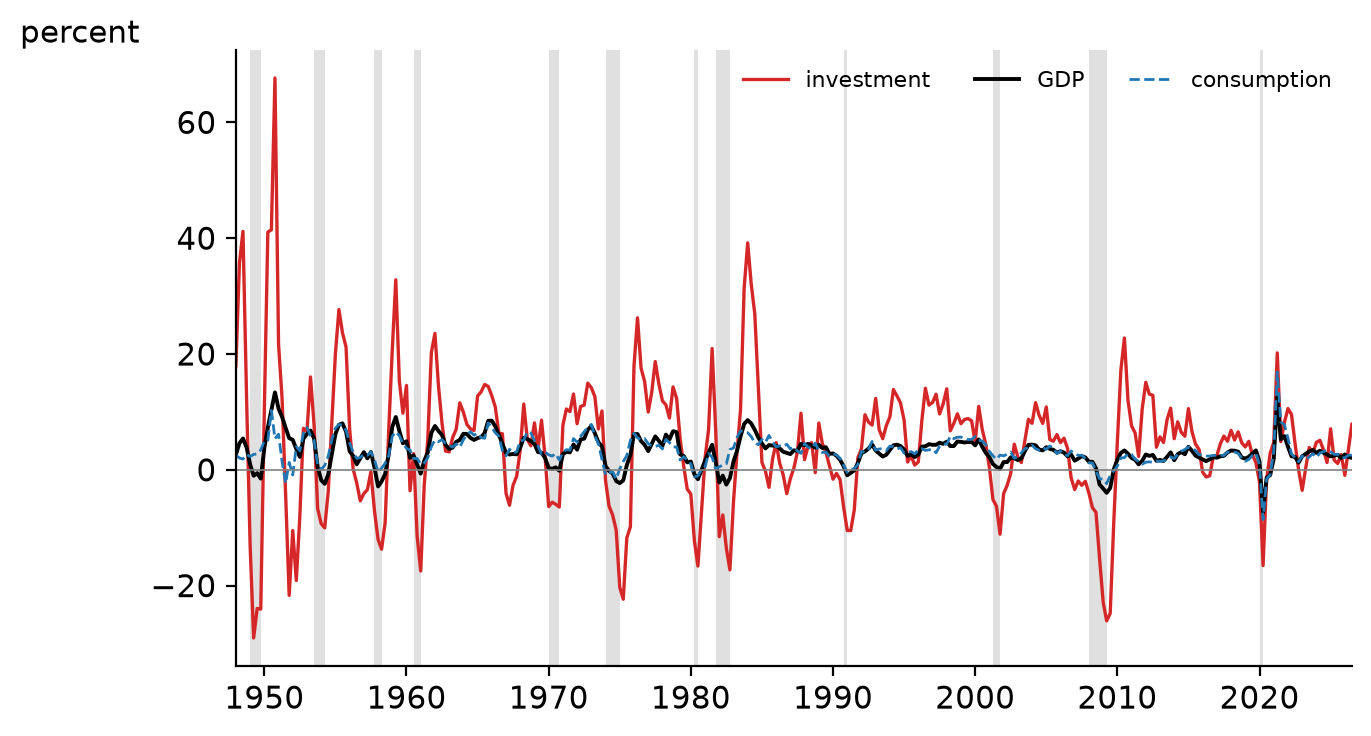

In [ ]:
fig, ax = plt.subplots(figsize=(7.2, 4.0))
accelerator.draw_volatility(ax, {"investment": investment, "GDP": gdp, "consumption": consumption}, recessions)
style.save(fig, "InvestmentVolatility")

How much more investment moves: the standard deviations of the growth rates, and the slope of investment's growth on GDP's, $\text{cov}(g_{I}, g_{Y})/\text{var}(g_{Y})$, which says by how many percentage points investment's growth moves when GDP's moves by one. Weighted by investment's share of GDP, that slope is investment's share of the variance of GDP's growth: the shares of all the components add up to one.

In [ ]:
sd = {name: series.std() for name, series in (("GDP", gdp), ("consumption", consumption), ("investment", investment))}
both = pd.concat([investment, gdp], axis=1, sort=True).dropna()
slope = both.cov().iloc[0, 1] / both.iloc[:, 1].var()
share = (load("GPDIC1") / load("GDPC1")).mean()
print(f"{gdp.index[0]:%Y}Q{gdp.index[0].quarter} to {gdp.index[-1]:%Y}Q{gdp.index[-1].quarter}: standard deviation of four-quarter growth, percent:",
      ", ".join(f"{name} {value:.1f}" for name, value in sd.items()))
print(f"investment's over GDP's: {sd['investment'] / sd['GDP']:.1f}; slope of investment's growth on GDP's: {slope:.1f}")
print(f"investment's average share of GDP: {share:.2f}; so it accounts for about {share * slope:.0%} of the variance of GDP's growth")

1948Q1 to 2026Q3: standard deviation of four-quarter growth, percent: GDP 2.6, consumption 2.3, investment 11.5
investment's over GDP's: 4.4; slope of investment's growth on GDP's: 3.5
investment's average share of GDP: 0.14; so it accounts for about 49% of the variance of GDP's growth


## The multiplier-accelerator

Samuelson's (1939) model: output is government spending plus consumption plus investment, consumption is a share $c$ of last period's income, and investment is $v$ times the change in consumption. So

$$
Y_{t} = G + c(1+v)Y_{t-1} - cvY_{t-2},
$$

whose steady state is $G/(1-c)$. Output cycles when the roots of $x^{2} - c(1+v)x + cv = 0$ are complex, that is when $c(1+v)^{2} < 4v$, and it converges when $cv < 1$ (with $c < 1$). `path` is output after government spending rises by 10 percent, for good, at $t = 0$, relative to the change's long-run effect: 0 is the old steady state and 1 the new.

In [ ]:
def cycles(c, v):
    return c * (1 + v) ** 2 < 4 * v  # the roots of x^2 - c(1+v)x + cv are complex


def stable(c, v):
    return c * v < 1  # the roots' product is cv; with c < 1, both roots are inside the unit circle


def path(c, v, periods=30, change=0.1):
    """Output from t = -1, in the old steady state, after G rises from 1 to 1 + change at t = 0."""
    Y = np.full(periods + 2, 1 / (1 - c))  # Y_{-2} and Y_{-1}: the old steady state
    for t in range(2, periods + 2):
        Y[t] = 1 + change + c * (1 + v) * Y[t - 1] - c * v * Y[t - 2]
    old, new = 1 / (1 - c), (1 + change) / (1 - c)
    return np.arange(-1, periods), (Y[1:] - old) / (new - old)

The map of the four regimes, and an example of each, numbered on the map: below the solid curve output cycles, and below the dashed one it converges.

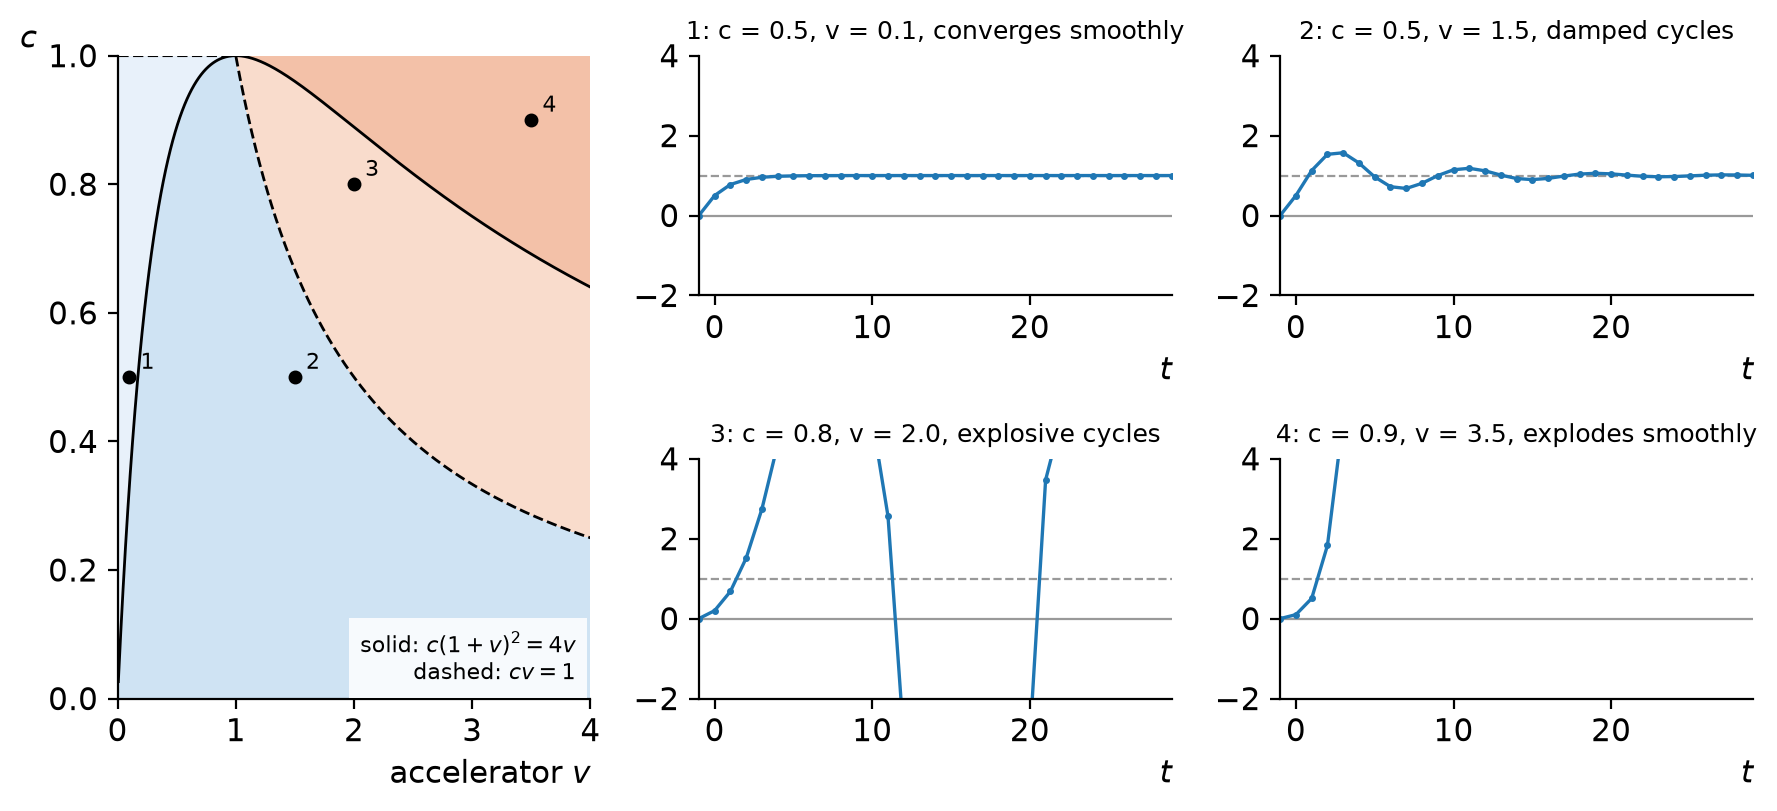

In [ ]:
examples = [(0.5, 0.1), (0.5, 1.5), (0.8, 2.0), (0.9, 3.5)]  # (c, v)
names = ["converges smoothly", "damped cycles", "explosive cycles", "explodes smoothly"]
fig = plt.figure(figsize=(9.0, 4.2))
grid = fig.add_gridspec(2, 3)
accelerator.draw_regimes(fig.add_subplot(grid[:, 0]), cycles, stable, examples=examples)
for i, ((c, v), name) in enumerate(zip(examples, names)):
    ax = fig.add_subplot(grid[i // 2, 1 + i % 2])
    accelerator.draw_path(ax, *path(c, v), label=f"{i + 1}: c = {c}, v = {v}, {name}")
fig.tight_layout()
style.save(fig, "MultiplierAccelerator")

## The chapter's results

In [ ]:
for (c, v), name in zip(examples, names):
    assert cycles(c, v) == ("cycles" in name) and stable(c, v) == (name in ("converges smoothly", "damped cycles")), name
assert 0.4 < share * slope < 0.6  # investment accounts for about half of the variance of GDP's growth
assert sd["investment"] / sd["GDP"] > 3 and sd["consumption"] < sd["GDP"]  # investment several times as volatile

## With sliders

Where the marginal propensity to consume and the accelerator put the economy on the map, and the path of output after government spending rises. The axes are fixed; a path that explodes leaves the frame.

In [ ]:
accelerator.sliders_samuelson(path, cycles, stable)